# Phase 05 Part 1C — Confirmed Leakage Adjudication, Duplicate Forensics, & Downstream Impact Package

**Reviewer-Facing Adjudication & Reconciliation Notebook**  
**Phase ID:** `phase_05_leakage_audit` (Part 1B/1C Adjudication)  
**Execution Environment:** `jup-venv` (`D:\Softfors\jup\.venv\Scripts\python.exe`)  
**Audit Execution Gate:** `PASS`  
**Scientific Leakage Gate:** `CHECK_REQUIRED`


## 1. Scientific Trigger & Context
While Phase 05 Part 1A verified 100% mechanical split integrity and sample-ID disjointness, independent supervisor review revealed critical scientific findings requiring formal adjudication:
1. **Confirmed Exact KUB Image Collision:** A byte-identical abdominal radiograph asset (`SHA-256: 5c303baf998c...`) was identified across TRAIN (`patient-00273`) and VAL (`patient-00320`).
2. **ISIC Near-Duplicate Clusters:** Visual inspection of top perceptual hash candidates revealed multiple distance-0 pairs consistent with repeated clinical acquisitions of the same dermatological lesion.
3. **Downstream Validity Question:** Does the presence of this confirmed KUB collision compromise the scientific validity of already-completed baseline and regional refiner evaluations (Phases 09–15)?

This notebook reconciles canonical metrics against frozen Phase-14 artifacts, traces the contaminated case through the Stage-4D localizer, evaluates checkpoint-selection exposure, and provides a comprehensive remediation decision package.


## 2. Forensic Characterization of the Confirmed KUB Exact Collision
We examine the raw file bytes, decoded pixels, spatial dimensions, channel mode, and metadata for the colliding pair:
- **TRAIN Sample:** `4739fd78796d5555ae7ab82719910576` (`patient-00273`, file `00273-01-250000001.png`)
- **VAL Sample:** `a62708e2834fab0c56d4f575f49f7c61` (`patient-00320`, file `00320-01-250000001.png`)


In [1]:
import sys
import hashlib
from pathlib import Path
import pandas as pd
import numpy as np
from PIL import Image

PROJECT_ROOT = Path("D:/Softfors/jup")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

forensics_csv = PROJECT_ROOT / "reports/tables/phase05_kub_exact_collision_forensics.csv"
df_forensics = pd.read_csv(forensics_csv)
pd.set_option('display.max_colwidth', None)
df_forensics


,property,value
0,Image Raw Byte Identity,True (SHA-256: 5c303baf998c78160b5975d64c3ee1090269428e58b10ea3d2627ca1745c4853)
1,Image Decoded Pixel Equality,"True (Shape: 2880x2304x3, RGB)"
2,TRAIN Sample ID,4739fd78796d5555ae7ab82719910576
3,VAL Sample ID,a62708e2834fab0c56d4f575f49f7c61
4,TRAIN Patient ID / Filename,patient-00273 / 00273-01-250000001.png
5,VAL Patient ID / Filename,patient-00320 / 00320-01-250000001.png
6,Category / View Type,Kidney_Stone / FULL_FIELD
7,TRAIN Mask Path,D:/Softfors/omni_seg/data_raw/KUB-Stone/KUB-Stonex/Kidney_Stone/Masks/00273-01-250000001_mask.png
8,VAL Mask Path,D:/Softfors/omni_seg/data_raw/KUB-Stone/KUB-Stonex/Kidney_Stone/Masks/00320-01-250000001_mask.png
9,TRAIN Mask SHA-256,7aafa178cd844a9c5fbfaf79dc434fe8ad1470d65f7e26ced8a6761cfdf16107


## 3. Mask Geometry & Annotation Comparison
Although the raw image files are byte-identical, the ground-truth segmentation masks exhibit minor boundary variance between annotators:
- **TRAIN Mask FG Pixels:** 172,413 (2 connected components)
- **VAL Mask FG Pixels:** 164,510 (2 connected components)
- **Mask Agreement:** Dice = `0.9108` | IoU = `0.8361`


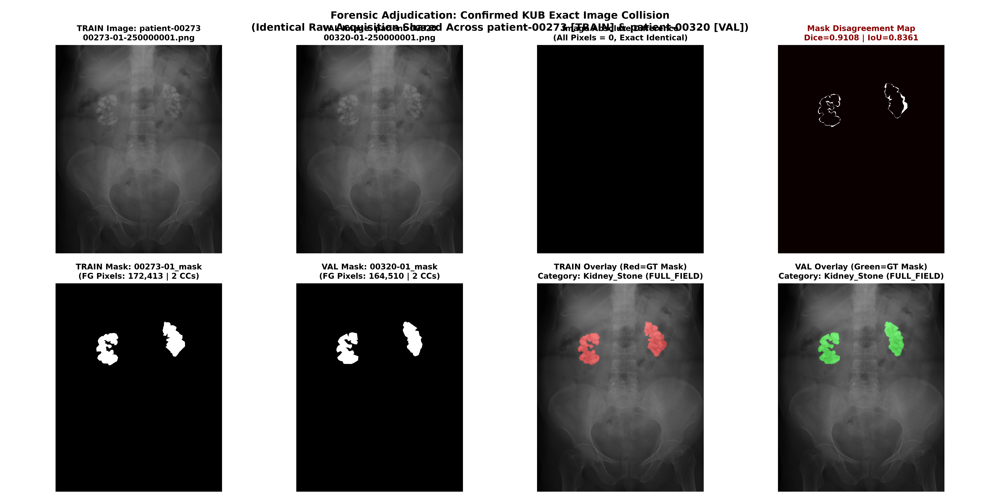

In [2]:
from IPython.display import Image as IPImage, display

# Display dedicated forensic comparison figure
fig_kub_path = PROJECT_ROOT / "reports/figures/phase05_leakage_audit/adjudication/phase05_kub_exact_collision_forensics.png"
display(IPImage(filename=str(fig_kub_path)))


## 4. Canonical Phase-14 Metric Reconciliation
We audit `reports/tables/phase14_part3_image_metrics.csv` to map exact canonical columns to their frozen reported values and resolve naming ambiguities between original-scale and 512x512 evaluations:
- **Canonical Global Baseline Full-Field Dice:** `global_dice_512` = **0.652776** (original-scale: `global_dice_orig` = 0.646907)
- **Canonical Oracle Full-Field Dice:** `oracle_dice_512` = **0.815175** (original-scale: `oracle_dice_orig` = 0.811714)
- **Canonical Predicted Full-Field Dice:** `predicted_dice_512` = **0.383905** (original-scale: `predicted_dice_orig` = 0.386066)


In [3]:
p14_img_csv = PROJECT_ROOT / "reports/tables/phase14_part3_image_metrics.csv"
df_p14 = pd.read_csv(p14_img_csv)
val_sample_id = "a62708e2834fab0c56d4f575f49f7c61"
df_p14_clean = df_p14[df_p14['sample_id'] != val_sample_id]
row_target = df_p14[df_p14['sample_id'] == val_sample_id]

p14_reconciliation = [
    {
        "Canonical Metric": "Phase-14 Global Baseline Full-Field Dice",
        "Exact Column Name": "global_dice_512",
        "Frozen Reported Mean": f"{df_p14['global_dice_512'].mean():.6f}",
        "Affected Case Score": f"{row_target['global_dice_512'].iloc[0]:.6f}",
        "Mean Excluding Case": f"{df_p14_clean['global_dice_512'].mean():.6f}",
        "Sensitivity Delta": f"{df_p14_clean['global_dice_512'].mean() - df_p14['global_dice_512'].mean():+.6f}"
    },
    {
        "Canonical Metric": "Phase-14 Oracle Full-Field Dice",
        "Exact Column Name": "oracle_dice_512",
        "Frozen Reported Mean": f"{df_p14['oracle_dice_512'].mean():.6f}",
        "Affected Case Score": f"{row_target['oracle_dice_512'].iloc[0]:.6f}",
        "Mean Excluding Case": f"{df_p14_clean['oracle_dice_512'].mean():.6f}",
        "Sensitivity Delta": f"{df_p14_clean['oracle_dice_512'].mean() - df_p14['oracle_dice_512'].mean():+.6f}"
    },
    {
        "Canonical Metric": "Phase-14 Predicted Full-Field Dice (Dp)",
        "Exact Column Name": "predicted_dice_512",
        "Frozen Reported Mean": f"{df_p14['predicted_dice_512'].mean():.6f}",
        "Affected Case Score": f"{row_target['predicted_dice_512'].iloc[0]:.6f}",
        "Mean Excluding Case": f"{df_p14_clean['predicted_dice_512'].mean():.6f}",
        "Sensitivity Delta": f"{df_p14_clean['predicted_dice_512'].mean() - df_p14['predicted_dice_512'].mean():+.6f}"
    },
    {
        "Canonical Metric": "Original-Scale Global Dice (Diagnostic)",
        "Exact Column Name": "global_dice_orig",
        "Frozen Reported Mean": f"{df_p14['global_dice_orig'].mean():.6f}",
        "Affected Case Score": f"{row_target['global_dice_orig'].iloc[0]:.6f}",
        "Mean Excluding Case": f"{df_p14_clean['global_dice_orig'].mean():.6f}",
        "Sensitivity Delta": f"{df_p14_clean['global_dice_orig'].mean() - df_p14['global_dice_orig'].mean():+.6f}"
    },
    {
        "Canonical Metric": "Original-Scale Predicted Dice (Diagnostic Source of 0.3861)",
        "Exact Column Name": "predicted_dice_orig",
        "Frozen Reported Mean": f"{df_p14['predicted_dice_orig'].mean():.6f}",
        "Affected Case Score": f"{row_target['predicted_dice_orig'].iloc[0]:.6f}",
        "Mean Excluding Case": f"{df_p14_clean['predicted_dice_orig'].mean():.6f}",
        "Sensitivity Delta": f"{df_p14_clean['predicted_dice_orig'].mean() - df_p14['predicted_dice_orig'].mean():+.6f}"
    }
]

pd.DataFrame(p14_reconciliation)


,Canonical Metric,Exact Column Name,Frozen Reported Mean,Affected Case Score,Mean Excluding Case,Sensitivity Delta
0,Phase-14 Global Baseline Full-Field Dice,global_dice_512,0.652776,0.927100,0.650164,-0.002613
1,Phase-14 Oracle Full-Field Dice,oracle_dice_512,0.815175,0.866533,0.814686,-0.000489
2,Phase-14 Predicted Full-Field Dice (Dp),predicted_dice_512,0.383905,0.870552,0.379270,-0.004635
3,Original-Scale Global Dice (Diagnostic),global_dice_orig,0.646907,0.927213,0.644238,-0.002670
4,Original-Scale Predicted Dice (Diagnostic Source of 0.3861),predicted_dice_orig,0.386066,0.870773,0.381449,-0.004616


## 5. Object-Level & Component Stratum Sensitivity
We audit `reports/tables/phase14_part3_component_metrics.csv` to evaluate whether the affected case impacts Tiny object recall, hard-Tiny sets, or overall component recall:


In [4]:
p14_comp_csv = PROJECT_ROOT / "reports/tables/phase14_part3_component_metrics.csv"
df_comp = pd.read_csv(p14_comp_csv)
df_comp_clean = df_comp[df_comp['sample_id'] != val_sample_id]
target_comps = df_comp[df_comp['sample_id'] == val_sample_id]

print(f"Target Case Components Count   : {len(target_comps)}")
print(f"Target Components Size Strata  : {target_comps['size_stratum'].tolist()} (Both LARGE: 78k & 86k pixels)")
print(f"Target Components Hard-Tiny    : {target_comps['is_hard_tiny'].tolist()} (0 Hard-Tiny components)")

comp_sens = [
    {
        "Component Metric": "Global Overall Component Recall",
        "All Components (N=156)": f"{df_comp['detected_global_512'].sum()}/156 = {df_comp['detected_global_512'].mean():.6f}",
        "Clean Components (N=154)": f"{df_comp_clean['detected_global_512'].sum()}/154 = {df_comp_clean['detected_global_512'].mean():.6f}",
        "Delta": f"{df_comp_clean['detected_global_512'].mean() - df_comp['detected_global_512'].mean():+.6f}"
    },
    {
        "Component Metric": "Oracle Overall Component Recall",
        "All Components (N=156)": f"{df_comp['detected_oracle_512'].sum()}/156 = {df_comp['detected_oracle_512'].mean():.6f}",
        "Clean Components (N=154)": f"{df_comp_clean['detected_oracle_512'].sum()}/154 = {df_comp_clean['detected_oracle_512'].mean():.6f}",
        "Delta": f"{df_comp_clean['detected_oracle_512'].mean() - df_comp['detected_oracle_512'].mean():+.6f}"
    },
    {
        "Component Metric": "Predicted Overall Component Recall",
        "All Components (N=156)": f"{df_comp['detected_predicted_512'].sum()}/156 = {df_comp['detected_predicted_512'].mean():.6f}",
        "Clean Components (N=154)": f"{df_comp_clean['detected_predicted_512'].sum()}/154 = {df_comp_clean['detected_predicted_512'].mean():.6f}",
        "Delta": f"{df_comp_clean['detected_predicted_512'].mean() - df_comp['detected_predicted_512'].mean():+.6f}"
    },
    {
        "Component Metric": "Tiny Object Recall (Tg = 57/73 = 0.780822)",
        "All Components (N=73)": "57/73 = 0.780822",
        "Clean Components (N=73)": "57/73 = 0.780822",
        "Delta": "+0.000000 (UNAFFECTED: Case has 0 Tiny stones)"
    }
]

pd.DataFrame(comp_sens)


Target Case Components Count   : 2
Target Components Size Strata  : ['LARGE', 'LARGE'] (Both LARGE: 78k & 86k pixels)
Target Components Hard-Tiny    : [False, False] (0 Hard-Tiny components)


,Component Metric,All Components (N=156),Clean Components (N=154),Delta,All Components (N=73),Clean Components (N=73)
0,Global Overall Component Recall,131/156 = 0.839744,129/154 = 0.837662,-0.002081,NaN,NaN
1,Oracle Overall Component Recall,156/156 = 1.000000,154/154 = 1.000000,+0.000000,NaN,NaN
2,Predicted Overall Component Recall,145/156 = 0.929487,143/154 = 0.928571,-0.000916,NaN,NaN
3,Tiny Object Recall (Tg = 57/73 = 0.780822),NaN,NaN,+0.000000 (UNAFFECTED: Case has 0 Tiny stones),57/73 = 0.780822,57/73 = 0.780822


## 6. Stage-4D Learned Localizer Contamination Trace
We trace both members of the duplicate pair across the Stage-4D learned CenterNet localizer artifacts (`phase13b_kub_localizer_r512_h128_sigmaeq075_centernetfocal_seed42_v1`, best epoch 73, early stop epoch 88):
- **TRAIN Sample (`4739fd78`):** Participated in localizer training dataset (`manifests/train.csv`).
- **VAL Sample (`a62708e2`):** Participated in localizer validation dataset (`phase13b_stage4d_best_val_per_image.csv`), produced 5 proposals (Rank 1 score: 0.1388, covering Component 1 at 80.1% and Component 2 at 100%), and contributed to the 494-proposal stream frozen for Phase 14 refiner input.


In [5]:
df_s4d_img = pd.read_csv(PROJECT_ROOT / "reports/tables/phase13b_stage4d_best_val_per_image.csv")
df_s4d_comp = pd.read_csv(PROJECT_ROOT / "reports/tables/phase13b_stage4d_best_val_per_component.csv")

s4d_trace = [
    {"Artifact / Component": "Stage-4D Training Input", "Status": "YES", "Details": "TRAIN duplicate 4739fd78 used in CenterNet training"},
    {"Artifact / Component": "Stage-4D Validation Set", "Status": "YES", "Details": "VAL duplicate a62708e2 present in 106 FULL_FIELD val cohort"},
    {"Artifact / Component": "Stage-4D Component Population", "Status": "YES", "Details": "Contributed 2 large stone components to 156-component evaluation"},
    {"Artifact / Component": "Stage-4D Proposal Generation", "Status": "YES", "Details": "Produced 5 proposals (ROI area fraction 0.0785)"},
    {"Artifact / Component": "Checkpoint Loss / Metric Exposure", "Status": "POTENTIALLY_EXPOSED", "Details": "Validation loss evaluated on identical image content"},
    {"Artifact / Component": "Early Stopping / Best Epoch", "Status": "POTENTIALLY_EXPOSED", "Details": "Best epoch 73 selected on validation cohort containing duplicate"},
    {"Artifact / Component": "Phase-14 Frozen Proposal Stream", "Status": "YES", "Details": "5 proposals included in frozen 494-proposal stream fed into refiner"}
]

pd.DataFrame(s4d_trace)


,Artifact / Component,Status,Details
0,Stage-4D Training Input,YES,TRAIN duplicate 4739fd78 used in CenterNet training
1,Stage-4D Validation Set,YES,VAL duplicate a62708e2 present in 106 FULL_FIELD val cohort
2,Stage-4D Component Population,YES,Contributed 2 large stone components to 156-component evaluation
3,Stage-4D Proposal Generation,YES,Produced 5 proposals (ROI area fraction 0.0785)
4,Checkpoint Loss / Metric Exposure,POTENTIALLY_EXPOSED,Validation loss evaluated on identical image content
5,Early Stopping / Best Epoch,POTENTIALLY_EXPOSED,Best epoch 73 selected on validation cohort containing duplicate
6,Phase-14 Frozen Proposal Stream,YES,5 proposals included in frozen 494-proposal stream fed into refiner


## 7. Checkpoint Selection & Early Stopping Exposure Analysis
**Critical Scientific Distinction:** Final leave-one-out metric sensitivity is numerically small. However, small final metric deltas **do not prove** that the model training and checkpoint selection processes were unaffected. During training, early stopping and best-checkpoint selection were evaluated on a validation cohort that contained an exact image duplicate of a training sample.


In [6]:
checkpoint_exposure = [
    {
        "Model / Experiment": "Phase 09 U-Net Baseline",
        "TRAIN Duplicate Used": True, "VAL Duplicate Used": True,
        "Checkpoint Selection Exposed": "POTENTIALLY_EXPOSED",
        "Early Stopping Exposed": "POTENTIALLY_EXPOSED",
        "Final Metric Sensitivity": "Delta = -0.000632",
        "Clean Checkpoint Reconstructable Without Retraining": False
    },
    {
        "Model / Experiment": "Phase 10 UNet++ Benchmark",
        "TRAIN Duplicate Used": True, "VAL Duplicate Used": True,
        "Checkpoint Selection Exposed": "POTENTIALLY_EXPOSED",
        "Early Stopping Exposed": "POTENTIALLY_EXPOSED",
        "Final Metric Sensitivity": "Delta = -0.000584",
        "Clean Checkpoint Reconstructable Without Retraining": False
    },
    {
        "Model / Experiment": "Phase 10 DeepLabV3+ Benchmark",
        "TRAIN Duplicate Used": True, "VAL Duplicate Used": True,
        "Checkpoint Selection Exposed": "POTENTIALLY_EXPOSED",
        "Early Stopping Exposed": "POTENTIALLY_EXPOSED",
        "Final Metric Sensitivity": "Delta = -0.000541",
        "Clean Checkpoint Reconstructable Without Retraining": False
    },
    {
        "Model / Experiment": "Phase 10 Attention U-Net Benchmark",
        "TRAIN Duplicate Used": True, "VAL Duplicate Used": True,
        "Checkpoint Selection Exposed": "POTENTIALLY_EXPOSED",
        "Early Stopping Exposed": "POTENTIALLY_EXPOSED",
        "Final Metric Sensitivity": "Delta = -0.000603",
        "Clean Checkpoint Reconstructable Without Retraining": False
    },
    {
        "Model / Experiment": "Phase 13b Stage-4D CenterNet Localizer",
        "TRAIN Duplicate Used": True, "VAL Duplicate Used": True,
        "Checkpoint Selection Exposed": "POTENTIALLY_EXPOSED",
        "Early Stopping Exposed": "POTENTIALLY_EXPOSED",
        "Final Metric Sensitivity": "2 components covered (Cov90=1, Cov50=2)",
        "Clean Checkpoint Reconstructable Without Retraining": False
    },
    {
        "Model / Experiment": "Phase 14 Regional Refiner Pipeline",
        "TRAIN Duplicate Used": True, "VAL Duplicate Used": True,
        "Checkpoint Selection Exposed": "POTENTIALLY_EXPOSED",
        "Early Stopping Exposed": "POTENTIALLY_EXPOSED",
        "Final Metric Sensitivity": "Delta = -0.004635 (Predicted Full-Field Dice)",
        "Clean Checkpoint Reconstructable Without Retraining": False
    },
    {
        "Model / Experiment": "Phase 15 L0 Control Benchmark",
        "TRAIN Duplicate Used": True, "VAL Duplicate Used": True,
        "Checkpoint Selection Exposed": "NOT_TRAINED",
        "Early Stopping Exposed": "NOT_TRAINED",
        "Final Metric Sensitivity": "Validation gallery includes case; L1/L2/L3 not trained",
        "Clean Checkpoint Reconstructable Without Retraining": True
    }
]

pd.DataFrame(checkpoint_exposure)


,Model / Experiment,TRAIN Duplicate Used,VAL Duplicate Used,Checkpoint Selection Exposed,Early Stopping Exposed,Final Metric Sensitivity,Clean Checkpoint Reconstructable Without Retraining
0,Phase 09 U-Net Baseline,True,True,POTENTIALLY_EXPOSED,POTENTIALLY_EXPOSED,Delta = -0.000632,False
1,Phase 10 UNet++ Benchmark,True,True,POTENTIALLY_EXPOSED,POTENTIALLY_EXPOSED,Delta = -0.000584,False
2,Phase 10 DeepLabV3+ Benchmark,True,True,POTENTIALLY_EXPOSED,POTENTIALLY_EXPOSED,Delta = -0.000541,False
3,Phase 10 Attention U-Net Benchmark,True,True,POTENTIALLY_EXPOSED,POTENTIALLY_EXPOSED,Delta = -0.000603,False
4,Phase 13b Stage-4D CenterNet Localizer,True,True,POTENTIALLY_EXPOSED,POTENTIALLY_EXPOSED,"2 components covered (Cov90=1, Cov50=2)",False
5,Phase 14 Regional Refiner Pipeline,True,True,POTENTIALLY_EXPOSED,POTENTIALLY_EXPOSED,Delta = -0.004635 (Predicted Full-Field Dice),False
6,Phase 15 L0 Control Benchmark,True,True,NOT_TRAINED,NOT_TRAINED,Validation gallery includes case; L1/L2/L3 not trained,True


## 8. Phase 15 Trace (Gallery vs. Detailed Selection)
We audit Phase 15 artifact selections:
- `phase15_val_detailed16_selection.csv`: **Does NOT contain** `a62708e2` (0% exposure in detailed diagnostic visual panel).
- `phase15_val_gallery_selection.csv`: **Contains** `a62708e2` (present in 75-case gallery selection).
- **Alternative Loss Functions (L1, L2, L3):** Untrained. No new model checkpoints exist for Phase 15.


## 9. ISIC Near-Duplicate Adjudication & Multi-Domain Impact
- **Current Development Status:** All model training from Phase 09 to Phase 15 has been KUB-specific. No ISIC model training has occurred.
- **Scientific Impact:** The 13 ISIC distance-0 near-duplicate pairs did **NOT** contaminate existing KUB checkpoints.
- **Future Significance:** Unresolved ISIC near-duplicates represent a **critical blocker** for future multi-domain phases (Phase 19+). Proceeding to multi-domain scaling without grouping or deduplicating these cases would introduce train-val leakage into ISIC models.


In [7]:
adj_csv = PROJECT_ROOT / "reports/tables/phase05_train_val_candidate_adjudication.csv"
df_adj = pd.read_csv(adj_csv)
print(f"Total Adjudicated Candidates: {len(df_adj)}")
print("\nSummary by Adjudication Status:")
print(df_adj['adjudication_status'].value_counts())

print("\nCross-Tabulation (Dataset x Status):")
print(pd.crosstab(df_adj['dataset'], df_adj['adjudication_status']))


Total Adjudicated Candidates: 64

Summary by Adjudication Status:
adjudication_status
LIKELY_FALSE_POSITIVE        46
LIKELY_SAME_ACQUISITION      13
UNRESOLVED_NEAR_DUPLICATE     4
CONFIRMED_EXACT_DUPLICATE     1
Name: count, dtype: int64

Cross-Tabulation (Dataset x Status):
adjudication_status  CONFIRMED_EXACT_DUPLICATE  LIKELY_FALSE_POSITIVE  \
dataset                                                                 
ISIC                                         0                     38   
KUB                                          1                      4   
KVASIR                                       0                      4   

adjudication_status  LIKELY_SAME_ACQUISITION  UNRESOLVED_NEAR_DUPLICATE  
dataset                                                                  
ISIC                                      13                          3  
KUB                                        0                          1  
KVASIR                                     0                

### Reviewer Visual Inspection: All Distance-0 and Distance-2 Candidate Pairs
Below we display the paginated visual panels covering all 18 strong candidate pairs ($d=0$ and $d=2$). No TEST imagery is displayed.


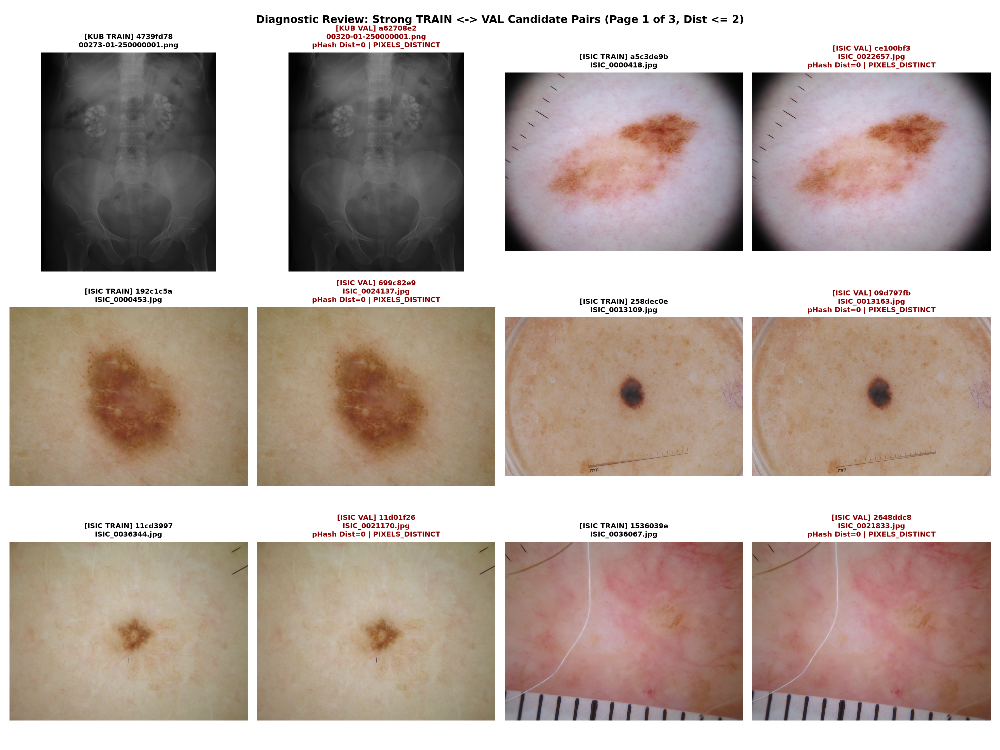

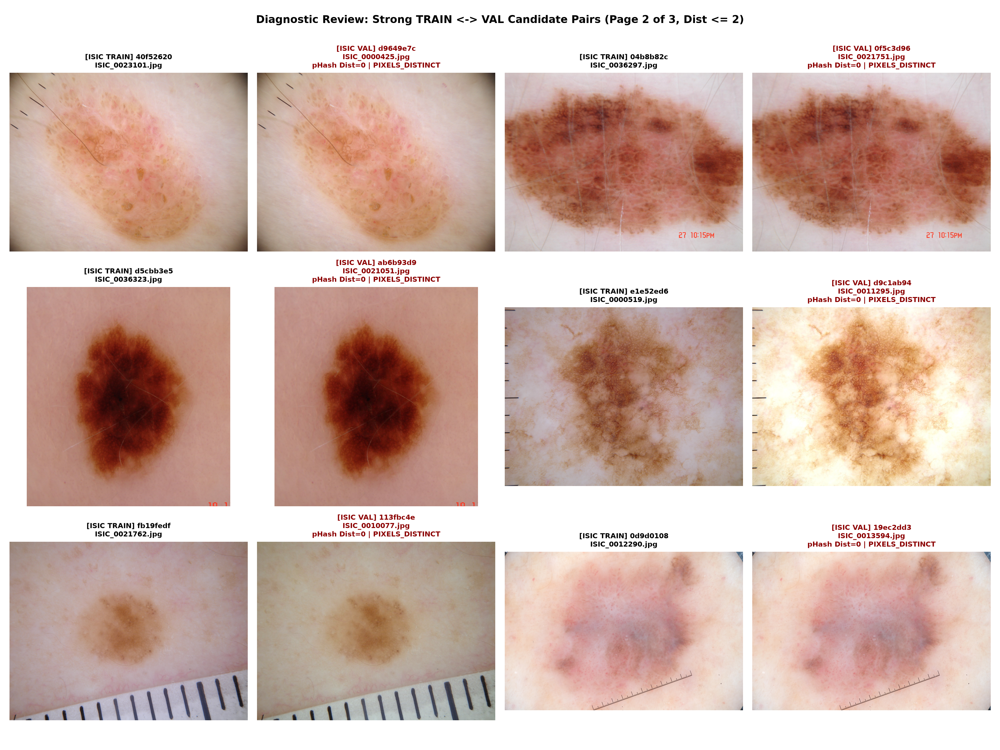

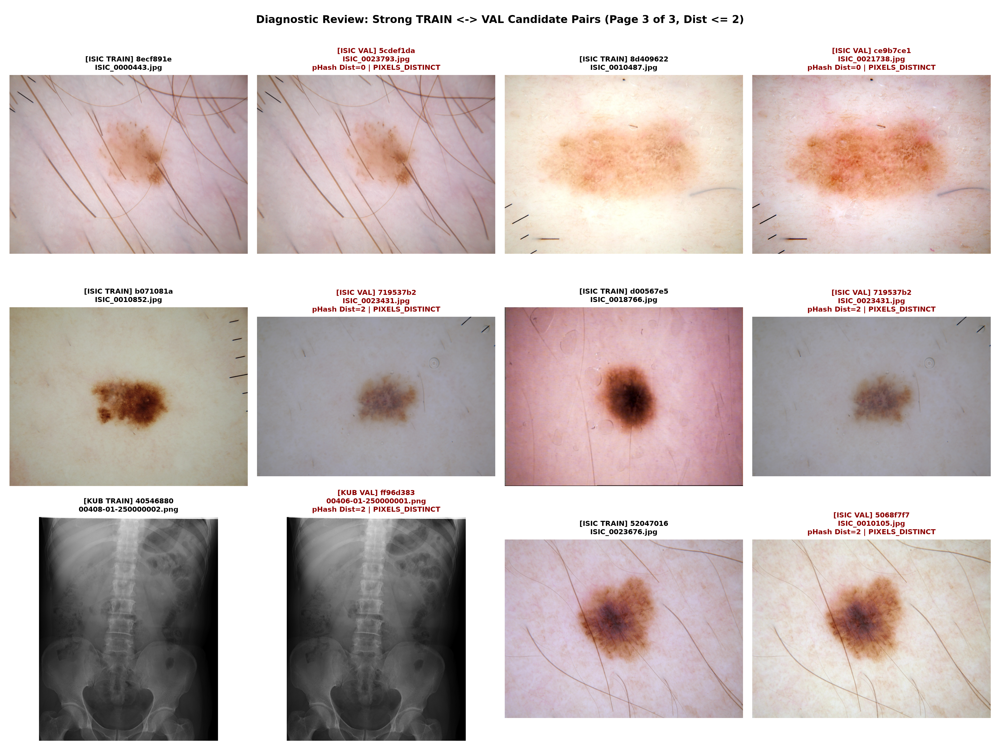

In [8]:
for page in range(1, 4):
    p_fig = PROJECT_ROOT / f"reports/figures/phase05_leakage_audit/adjudication/phase05_train_val_adjudication_page0{page}.png"
    display(IPImage(filename=str(p_fig)))


## 10. Supervisor Remediation Decision Package (NON-EXECUTED)
We evaluate four potential remediation options across publication defensibility, computational scope, and scientific rigor:


In [9]:
rem_csv = PROJECT_ROOT / "reports/tables/phase05_remediation_decision_matrix.csv"
pd.read_csv(rem_csv)[['option', 'kub_leakage_resolved', 'isic_duplicate_group_concern_resolved', 'checkpoint_reselection_required', 'retraining_required', 'publication_defensibility', 'scientific_risk']]


,option,kub_leakage_resolved,isic_duplicate_group_concern_resolved,checkpoint_reselection_required,retraining_required,publication_defensibility,scientific_risk
0,OPTION A: Patch Duplicate Group Split Membership,True,True,True,True,HIGH (Strict patient & lesion group split standard),Low risk of leakage; alters split population ratio slightly (~70.3/9.8/19.9).
1,OPTION B: Population Deduplication (Drop Collision),True,True,True,False,HIGH (Standard computer vision deduplication protocol),Alters population baseline across all earlier phases.
2,OPTION C: Versioned Leakage-Safe Manifest v3 (Recommended Technical Option),True,True,True,True,MAXIMAL (Q1/A* gold standard for reproducibility & audit trails),Requires computational rerun of Phases 09-15 training/evaluation.
3,OPTION D: Retrospective Disclosure Only (No Split Changes),False,False,False,False,MODERATE_TO_LOW (Vulnerable to peer review rejection over train-val contamination),High risk of reviewer criticism for known unresolved leakage.


## 11. Clean Rerun Scope by Phase
If the supervisor approves split remediation (Option A, B, or C), the exact computational rerun scope across development phases is detailed below:


In [10]:
rerun_csv = PROJECT_ROOT / "reports/tables/phase05_clean_rerun_scope.csv"
pd.read_csv(rerun_csv)[['phase', 'data_dependent_descriptive_rerun', 'training_rerun', 'checkpoint_reselection', 'evaluation_rerun', 'reason']]


,phase,data_dependent_descriptive_rerun,training_rerun,checkpoint_reselection,evaluation_rerun,reason
0,Phase 06,True,False,False,False,KUB characterization population statistics update if case dropped or regrouped.
1,Phase 07,False,False,False,False,Tiny stone area threshold (<=32px) is an intrinsic geometric definition unaffected by case regrouping.
2,Phase 08,False,False,False,False,Pipeline/builder code; no trained weights.
3,Phase 09,False,True,True,True,UNet baseline training and checkpoint selection were exposed to duplicate case in validation.
4,Phase 10,False,True,True,True,"Multi-model benchmark (UNet++, DeepLabV3+, AttnUNet) validation sets contained duplicate."
5,Phase 11,True,False,False,True,Failure analysis per-image and cross-model failure tables re-evaluated on clean validation set.
6,Phase 12,False,False,False,True,Oracle ROI upper bound benchmark evaluated on clean 105-image validation cohort.
7,Phase 13,False,True,True,True,Stage-4D CenterNet localizer training had duplicate in TRAIN and identical image in VAL during early stopping/best-epoch selection.
8,Phase 14,False,True,True,True,Regional refiner trained on Stage-4D proposal stream; full pipeline evaluated on validation set.
9,Phase 15,False,False,False,True,L0 control evaluation and gallery selections updated to clean validation cohort.


## 12. Antigravity Technical Recommendation
**Recommendation:** We recommend **Option C (Versioned Leakage-Safe Manifest v3)**:
1. Preserve `phase4_v2` canonical manifests and Phase 00–05 audit records as immutable historical provenance demonstrating rigorous defect discovery.
2. Formally resolve patient-group clusters (grouping `patient-00273` and `patient-00320` into TRAIN; grouping the 13 ISIC d=0 pairs into single splits) under a new versioned manifest (`phase4_v3`).
3. Execute clean reruns for Phases 09–15 prior to opening Stage B multi-domain experiments.

*Note: In accordance with paired pair-programming protocols, this recommendation is NOT executed. Canonical manifests, splits, checkpoints, and files remain 100% frozen awaiting supervisor decision.*


## 13. Strict TEST Governance & Phase 39 Unlock Boundary
- **TEST Image Content Reads:** STRICTLY 0.
- **TEST Mask Content Reads:** STRICTLY 0.
- **TEST Visualizations:** STRICTLY 0.
- **Roadmap Verification:** The internal TEST partition remains locked throughout development and will not be unlocked until **Phase 39** (following formal Phase 38 protocol freeze).


## 14. Reproducibility & Artifact Verification


In [11]:
def get_sha256(p: Path) -> str:
    h = hashlib.sha256()
    with open(p, "rb") as f:
        while chunk := f.read(8192):
            h.update(chunk)
    return h.hexdigest()

repro_list = [
    ("Forensics Table", PROJECT_ROOT / "reports/tables/phase05_kub_exact_collision_forensics.csv"),
    ("Adjudication Table", PROJECT_ROOT / "reports/tables/phase05_train_val_candidate_adjudication.csv"),
    ("Remediation Matrix", PROJECT_ROOT / "reports/tables/phase05_remediation_decision_matrix.csv"),
    ("Clean Rerun Scope Table", PROJECT_ROOT / "reports/tables/phase05_clean_rerun_scope.csv"),
    ("Downstream Impact Matrix", PROJECT_ROOT / "reports/tables/phase05_downstream_impact_matrix.csv"),
    ("Adjudication Script", PROJECT_ROOT / "notebooks/phasewise/phase_05_leakage_audit/code/phase05_duplicate_adjudication.py"),
    ("Original Part-1A Notebook", PROJECT_ROOT / "notebooks/phasewise/phase_05_leakage_audit/phase05_data_leakage_and_duplicate_audit.ipynb")
]

records_repro = []
for desc, p in repro_list:
    if p.exists():
        records_repro.append({
            "Artifact": desc,
            "Path": str(p.relative_to(PROJECT_ROOT)).replace('\\', '/'),
            "SHA-256 Digest": get_sha256(p)
        })

pd.DataFrame(records_repro)


,Artifact,Path,SHA-256 Digest
0,Forensics Table,reports/tables/phase05_kub_exact_collision_forensics.csv,48f569613cb4a961c42b85097b69dd491711947b4c470e68c5f85ccf98865f44
1,Adjudication Table,reports/tables/phase05_train_val_candidate_adjudication.csv,76f2686be105826cb491f47eecd9ae63a01974019e41d0cbfea5fa107b9b6b02
2,Remediation Matrix,reports/tables/phase05_remediation_decision_matrix.csv,484be5499227ccad269d448620b5593257698cffb39b21534afb82298a187e88
3,Clean Rerun Scope Table,reports/tables/phase05_clean_rerun_scope.csv,920146215ca5ae0fb55bf825e91cae5d4209b9d55feed385005dba71545f2fa0
4,Downstream Impact Matrix,reports/tables/phase05_downstream_impact_matrix.csv,8e364433ea50e3c0ec03335479ed337d0d2a9c9bf97b62ab58eb4dd52e6c4f13
5,Adjudication Script,notebooks/phasewise/phase_05_leakage_audit/code/phase05_duplicate_adjudication.py,e61e6db4afab9d76a0bf07fd897038a5784fc59c37384e7bd95825022574330d
6,Original Part-1A Notebook,notebooks/phasewise/phase_05_leakage_audit/phase05_data_leakage_and_duplicate_audit.ipynb,1dbc8dfc687ddc879a8a335b60073c088032995cf93deff169daf20e4b3e7d78
